# Task 5: Data Analysis on CSV Files
**Objective:** Analyze sales data using Pandas  
**Tools:** Python, Pandas, Matplotlib, Jupyter Notebook  
**Dataset:** `sales_data.csv` (1,000 orders, Jan–Dec 2024)

## 1. Import libraries

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("charts", exist_ok=True)
plt.rcParams.update({"figure.figsize": (9, 5), "axes.grid": True, "grid.alpha": 0.3})

## 2. Load the CSV file

In [2]:
df = pd.read_csv("sales_data.csv", parse_dates=["Date"])
df.head()

,Order_ID,Date,Region,Product,Category,Quantity,Unit_Price,Payment_Method,Customer_Rating,Sales
0,ORD1258,2024-01-01,West,Laptop,Electronics,5,55718.48,Cash,4.0,278592.40
1,ORD1441,2024-01-01,South,Smartphone,Electronics,4,20626.58,UPI,5.0,82506.32
2,ORD1315,2024-01-01,East,Headphones,Electronics,4,2281.99,Credit Card,4.0,9127.96
3,ORD1788,2024-01-02,North,Pen Set,Stationery,4,242.45,UPI,5.0,969.80
4,ORD1627,2024-01-02,South,Smartphone,Electronics,1,22758.73,UPI,5.0,22758.73


## 3. Explore the data

In [3]:
print("Shape (rows, columns):", df.shape)
print()
df.info()

Shape (rows, columns): (1000, 10)

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Order_ID         1000 non-null   str           
 1   Date             1000 non-null   datetime64[us]
 2   Region           1000 non-null   str           
 3   Product          1000 non-null   str           
 4   Category         1000 non-null   str           
 5   Quantity         1000 non-null   int64         
 6   Unit_Price       1000 non-null   float64       
 7   Payment_Method   985 non-null    str           
 8   Customer_Rating  960 non-null    float64       
 9   Sales            1000 non-null   float64       
dtypes: datetime64[us](1), float64(3), int64(1), str(5)
memory usage: 78.3 KB


In [4]:
df.describe()

,Date,Quantity,Unit_Price,Customer_Rating,Sales
count,1000,1000.000000,1000.000000,960.000000,1000.000000
mean,2024-07-02 19:32:09.600000,3.994000,9248.392980,3.790625,36931.389400
min,2024-01-01 00:00:00,1.000000,108.060000,1.000000,108.930000
25%,2024-04-03 18:00:00,2.000000,255.752500,3.000000,1011.730000
50%,2024-06-28 12:00:00,4.000000,1954.780000,4.000000,6890.115000
75%,2024-10-03 00:00:00,6.000000,12432.687500,5.000000,43268.720000
max,2024-12-31 00:00:00,7.000000,60367.330000,5.000000,422571.310000
std,NaN,1.963624,15101.749824,1.097402,66973.599285


## 4. Handle missing values (NaN)

In [5]:
print("Missing values per column:")
print(df.isna().sum())

# Fill missing ratings with the median, missing payment method with 'Unknown'
df["Customer_Rating"] = df["Customer_Rating"].fillna(df["Customer_Rating"].median())
df["Payment_Method"] = df["Payment_Method"].fillna("Unknown")

print("\nMissing values after cleaning:", df.isna().sum().sum())

Missing values per column:
Order_ID            0
Date                0
Region              0
Product             0
Category            0
Quantity            0
Unit_Price          0
Payment_Method     15
Customer_Rating    40
Sales               0
dtype: int64

Missing values after cleaning: 0


## 5. Filtering rows, `loc[]` and `iloc[]`

In [6]:
# Filter: high-value orders in the South region
south_big = df[(df["Region"] == "South") & (df["Sales"] > 100000)]
print("South orders above 1,00,000:", len(south_big))
south_big.head()

South orders above 1,00,000: 34


,Order_ID,Date,Region,Product,Category,Quantity,Unit_Price,Payment_Method,Customer_Rating,Sales
12,ORD1260,2024-01-09,South,Smartphone,Electronics,7,20148.99,Cash,4.0,141042.93
49,ORD1524,2024-01-23,South,Smartphone,Electronics,5,22026.24,Debit Card,3.0,110131.20
63,ORD1794,2024-01-26,South,Laptop,Electronics,3,55685.62,UPI,5.0,167056.86
69,ORD1634,2024-01-31,South,Laptop,Electronics,6,55979.23,Credit Card,2.0,335875.38
103,ORD1722,2024-02-11,South,Laptop,Electronics,5,58861.41,UPI,2.0,294307.05


In [7]:
# loc  -> label based  |  iloc -> position based
print(df.loc[0:2, ["Order_ID", "Product", "Sales"]])
print()
print(df.iloc[0:3, 0:4])

  Order_ID     Product      Sales
0  ORD1258      Laptop  278592.40
1  ORD1441  Smartphone   82506.32
2  ORD1315  Headphones    9127.96

  Order_ID       Date Region     Product
0  ORD1258 2024-01-01   West      Laptop
1  ORD1441 2024-01-01  South  Smartphone
2  ORD1315 2024-01-01   East  Headphones


## 6. Key metrics

In [8]:
total_sales = df["Sales"].sum()
avg_order = df["Sales"].mean()
total_units = df["Quantity"].sum()

print(f"Total Sales        : {total_sales:,.2f}")
print(f"Average Order Value: {avg_order:,.2f}")
print(f"Total Units Sold   : {total_units:,}")
print(f"Total Orders       : {len(df):,}")

Total Sales        : 36,931,389.40
Average Order Value: 36,931.39
Total Units Sold   : 3,994
Total Orders       : 1,000


## 7. Sales by Product (`groupby` + `sum` + `plot`)

Product
Laptop          15259036.68
Smartphone      14772343.65
Desk             2531396.23
Office Chair     1681691.00
Headphones       1521446.47
Backpack          720366.08
Water Bottle      224704.25
Pen Set           143882.74
Notebook           76522.30
Name: Sales, dtype: float64


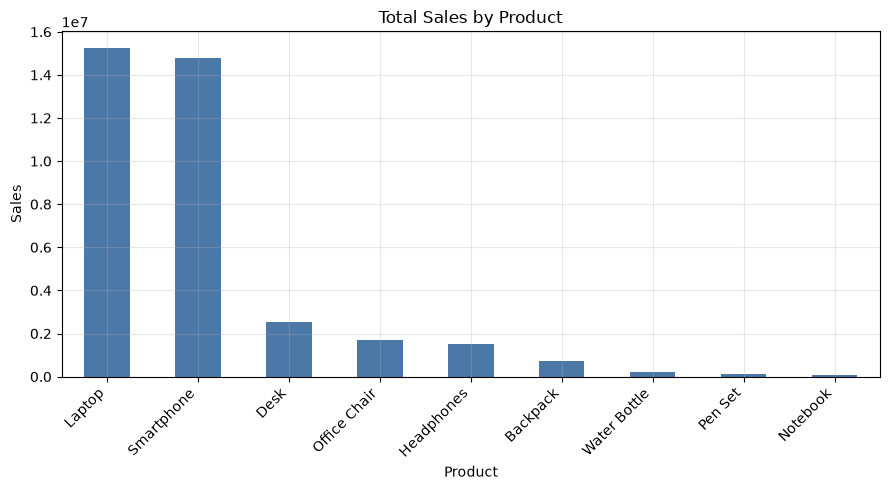

In [9]:
product_sales = df.groupby("Product")["Sales"].sum().sort_values(ascending=False)
print(product_sales)

ax = product_sales.plot(kind="bar", color="#4C78A8")
ax.set_title("Total Sales by Product")
ax.set_xlabel("Product"); ax.set_ylabel("Sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("charts/sales_by_product.png", dpi=150)
plt.show()

## 8. Sales by Region

Region
West     11832320.18
South    10215119.47
North     9997315.68
East      4886634.07
Name: Sales, dtype: float64


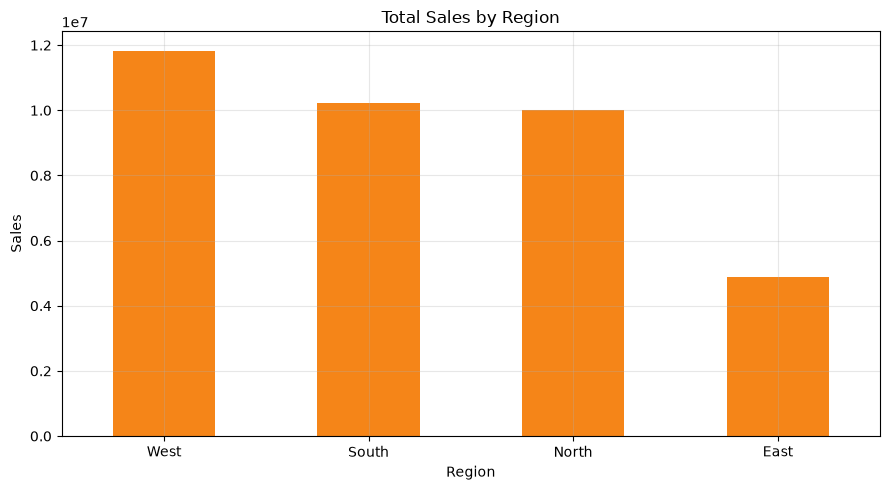

In [10]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
print(region_sales)

ax = region_sales.plot(kind="bar", color="#F58518")
ax.set_title("Total Sales by Region")
ax.set_xlabel("Region"); ax.set_ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("charts/sales_by_region.png", dpi=150)
plt.show()

## 9. Sales share by Category

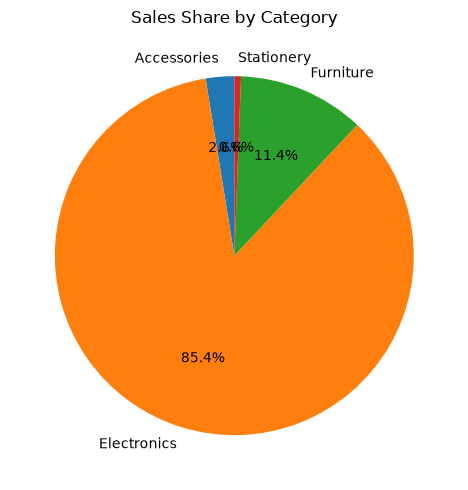

In [11]:
category_sales = df.groupby("Category")["Sales"].sum()
category_sales.plot(kind="pie", autopct="%1.1f%%", startangle=90, ylabel="")
plt.title("Sales Share by Category")
plt.tight_layout()
plt.savefig("charts/sales_by_category.png", dpi=150)
plt.show()

## 10. Monthly sales trend

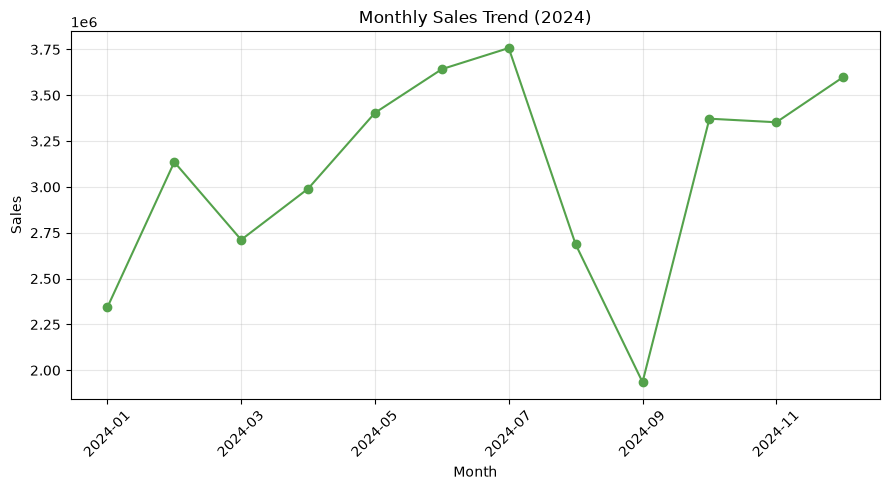

In [12]:
df["Month"] = df["Date"].dt.to_period("M")
monthly = df.groupby("Month")["Sales"].sum()
monthly.index = monthly.index.astype(str)

ax = monthly.plot(kind="line", marker="o", color="#54A24B")
ax.set_title("Monthly Sales Trend (2024)")
ax.set_xlabel("Month"); ax.set_ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("charts/monthly_trend.png", dpi=150)
plt.show()

## 11. Region × Category (stacked bar)

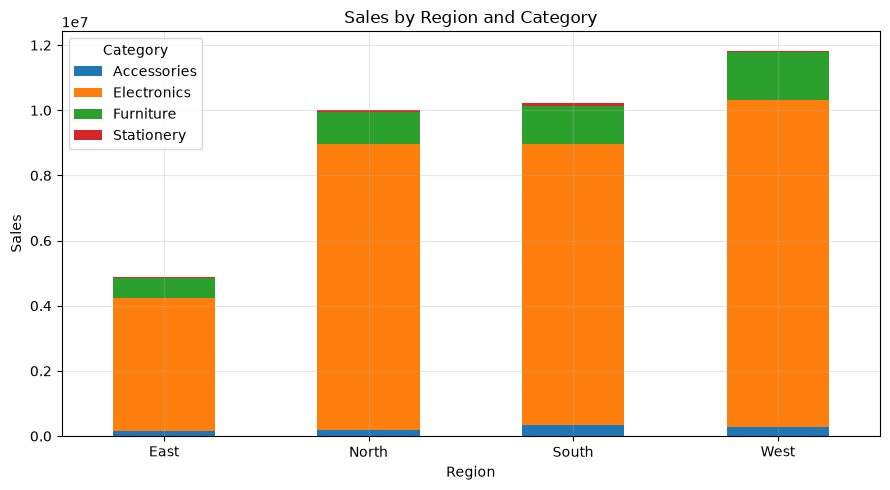

In [13]:
pivot = df.pivot_table(index="Region", columns="Category", values="Sales", aggfunc="sum")
ax = pivot.plot(kind="bar", stacked=True)
ax.set_title("Sales by Region and Category")
ax.set_ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("charts/region_category_stacked.png", dpi=150)
plt.show()

## 12. Payment method usage

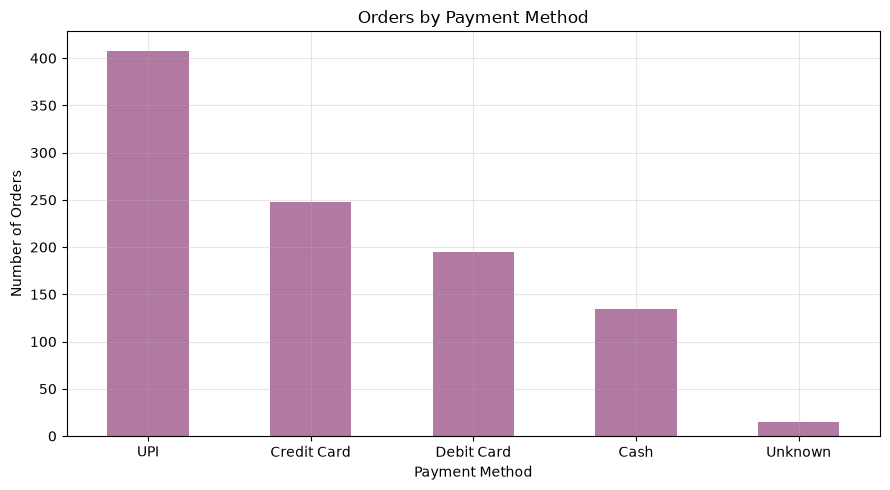

In [14]:
df["Payment_Method"].value_counts().plot(kind="bar", color="#B279A2")
plt.title("Orders by Payment Method")
plt.xlabel("Payment Method"); plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("charts/payment_methods.png", dpi=150)
plt.show()

## 13. Insights

In [15]:
top_product = product_sales.idxmax()
top_region = region_sales.idxmax()
top_category = category_sales.idxmax()
best_month = monthly.idxmax()
worst_month = monthly.idxmin()
top_payment = df["Payment_Method"].value_counts().idxmax()

print("KEY INSIGHTS")
print("-" * 50)
print(f"1. Top product        : {top_product} ({product_sales.max():,.0f})")
print(f"2. Top region         : {top_region} ({region_sales.max():,.0f})")
print(f"3. Top category       : {top_category} ({category_sales.max() / total_sales:.1%} of sales)")
print(f"4. Best month         : {best_month} ({monthly.max():,.0f})")
print(f"5. Weakest month      : {worst_month} ({monthly.min():,.0f})")
print(f"6. Most used payment  : {top_payment}")
print(f"7. Average rating     : {df['Customer_Rating'].mean():.2f} / 5")

KEY INSIGHTS
--------------------------------------------------
1. Top product        : Laptop (15,259,037)
2. Top region         : West (11,832,320)
3. Top category       : Electronics (85.4% of sales)
4. Best month         : 2024-07 (3,757,638)
5. Weakest month      : 2024-09 (1,935,158)
6. Most used payment  : UPI
7. Average rating     : 3.80 / 5


## 14. Interview Questions: quick answers

1. **What is Pandas used for?** Data loading, cleaning, analysis and manipulation of structured (tabular) data.
2. **What's a DataFrame?** A 2-D labelled table with rows and columns, where each column can have a different type.
3. **How do you read a CSV file?** `pd.read_csv("file.csv")`
4. **What is groupby()?** Splits data into groups by a column, applies a function (sum, mean, count) and combines the result: `df.groupby("Region")["Sales"].sum()`
5. **How do you filter rows?** Boolean indexing: `df[df["Sales"] > 1000]`, combine conditions with `&` and `|`.
6. **loc[] vs iloc[]?** `loc` selects by label/condition; `iloc` selects by integer position.
7. **What does .head() do?** Shows the first 5 rows (or `n` rows) of a DataFrame.
8. **How to create a bar chart?** `df.groupby("Region")["Sales"].sum().plot(kind="bar")`
9. **Shape of a DataFrame?** `df.shape` returns `(rows, columns)`.
10. **What is NaN?** "Not a Number": Pandas' marker for missing values. Detect with `isna()`, handle with `fillna()` or `dropna()`.